# 大模型微调 12：大模型扩展知识与简历项目参考

本篇整理 `12-分享资料` 和 `12-代码`。它不是一个新的训练项目，而是前面 ChatGLM + LoRA 项目的代码副本，以及围绕大模型岗位和项目实践补充的扩展资料：简历项目参考、模型基础知识、RAG 与向量数据库、推理加速、传统机器学习、TF-IDF 和大模型强化学习。

## 本篇的阅读方式

- **简历项目参考**：从项目目标、技术链、指标和工程产出中提炼项目表达方式；
- **基础知识扩展**：解释前面模型微调和 RAG 笔记中出现的底层组件；
- **强化学习扩展**：从 RLHF 四模型和 PPO 讲到 ReMax、GRPO、DPO、DPOP、TDPO、ORPO；
- **代码复核**：12 号 ChatGLM 代码与 11 号代码逐文件一致，重点复用 11 篇的实现结论，不重复抄录全部代码。

资料中的简历指标和课程宣传数据是原文件记录，应作为项目表达示例阅读，不当作当前环境重新测得的实验结果。

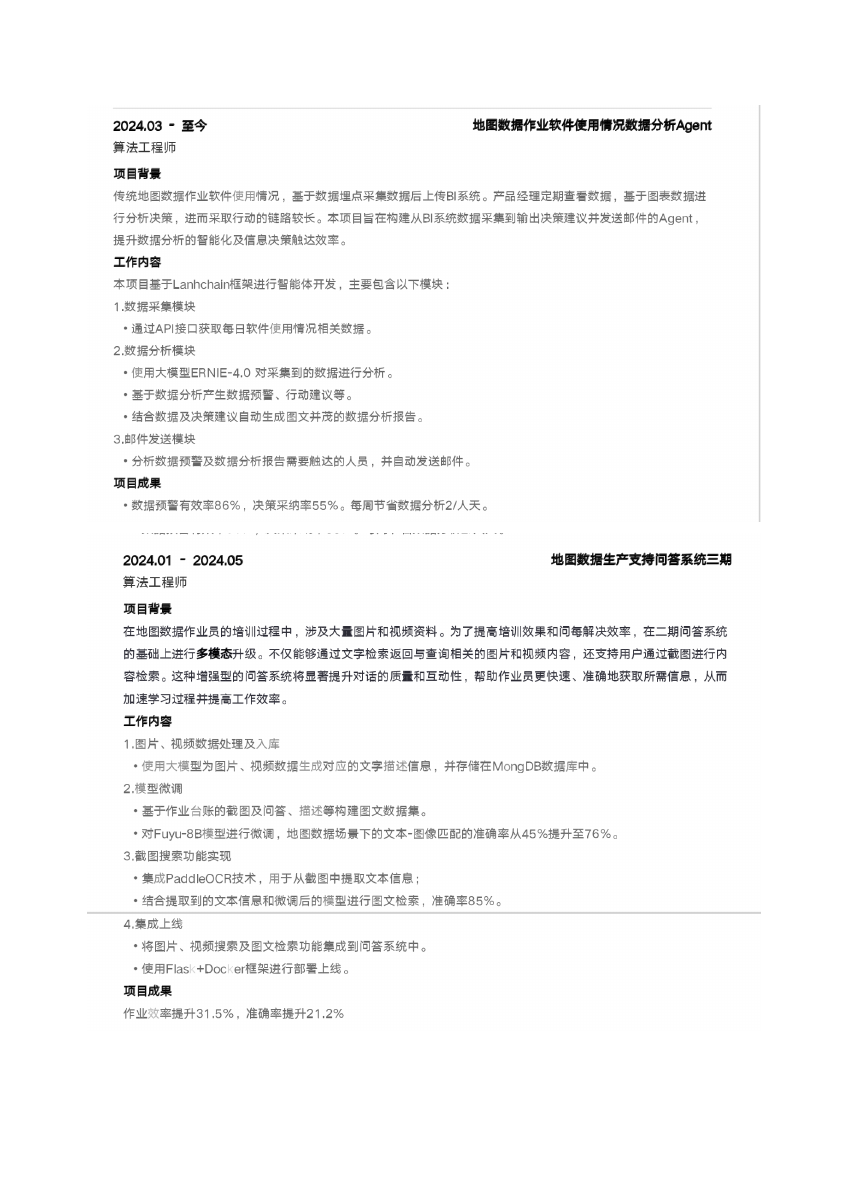

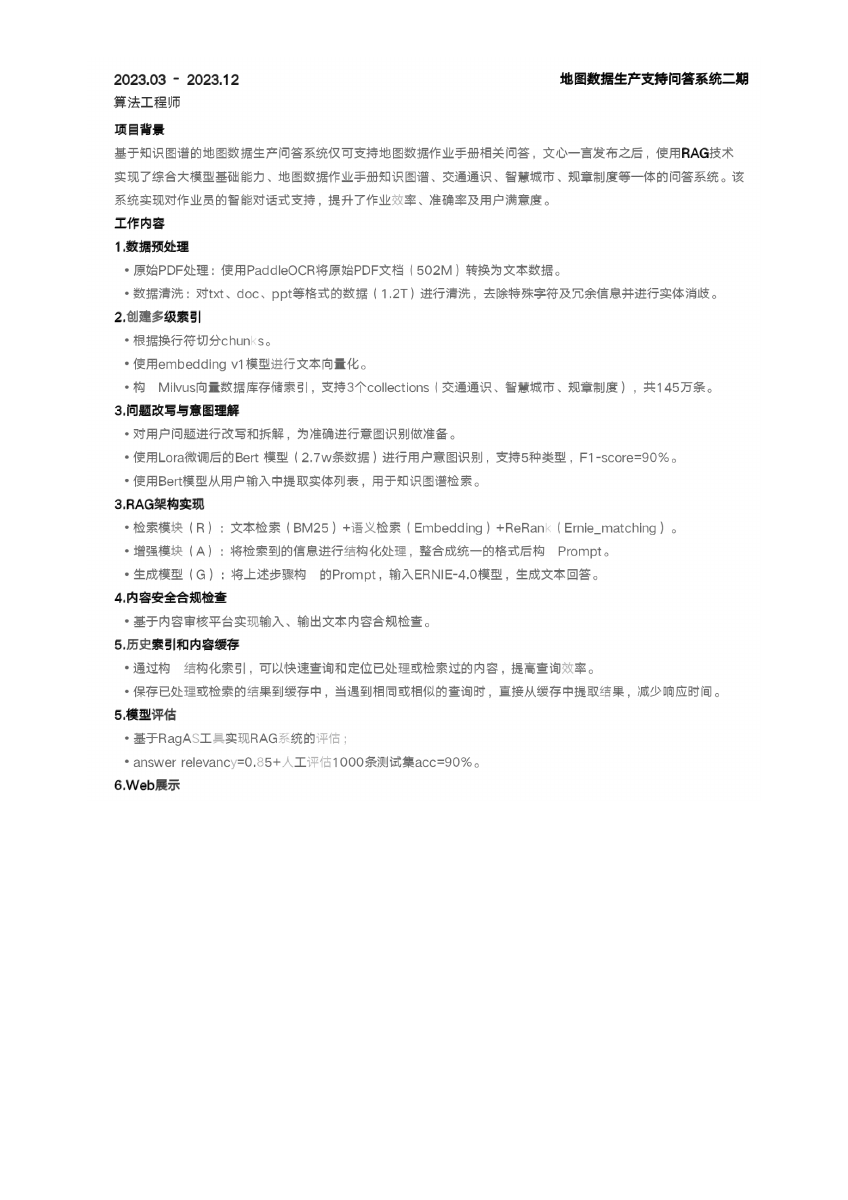

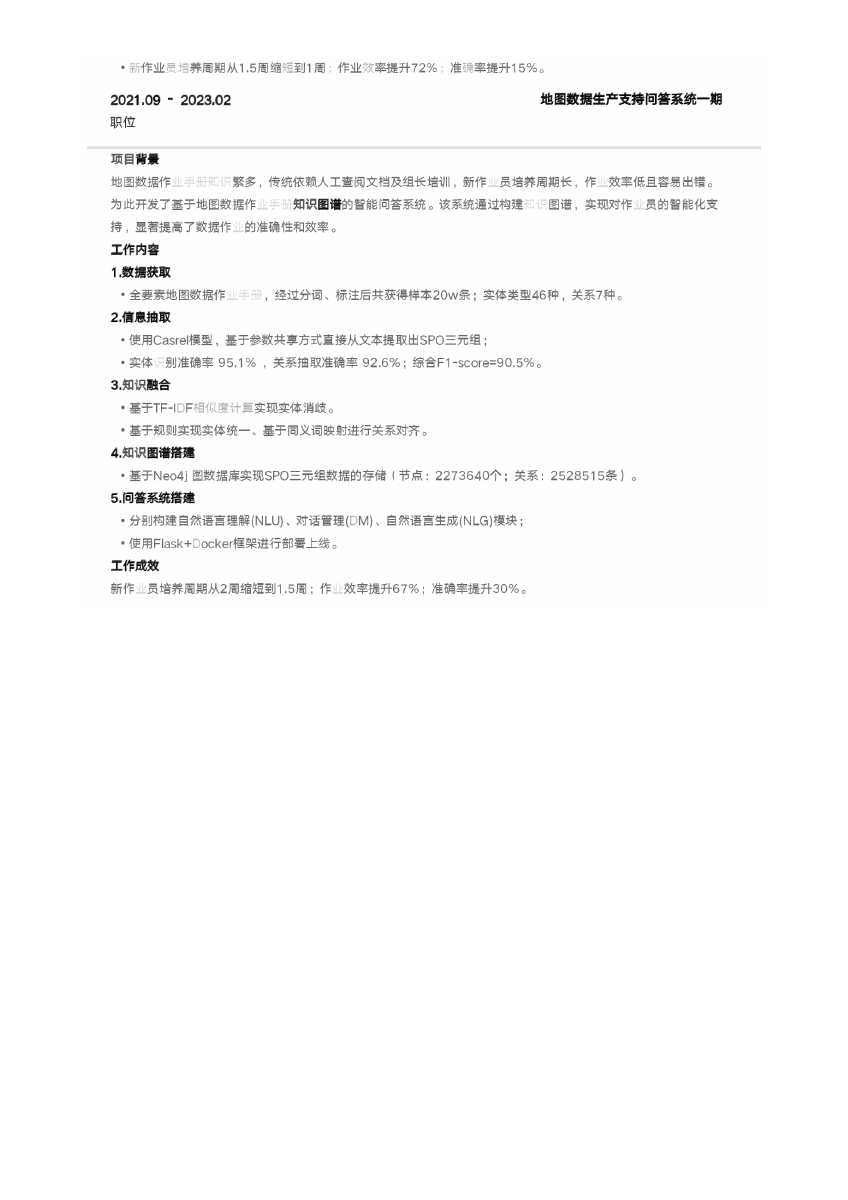

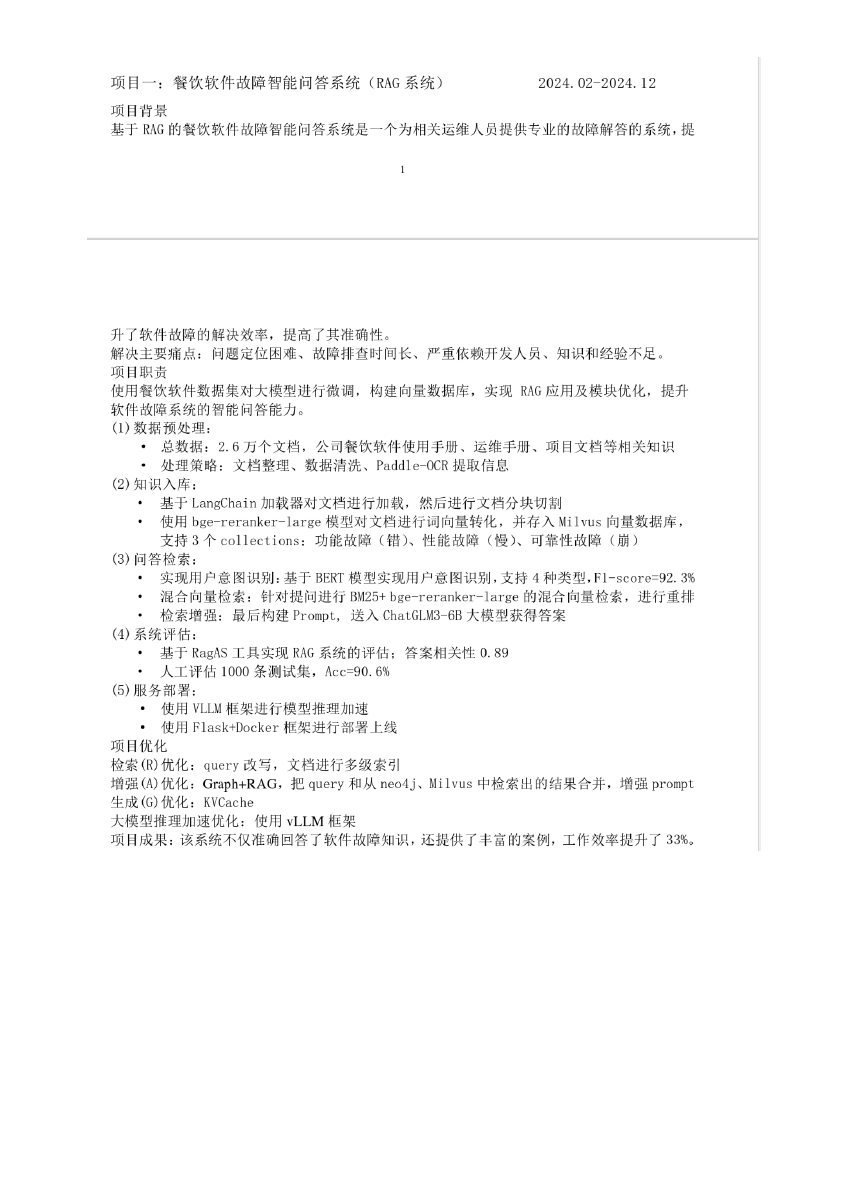

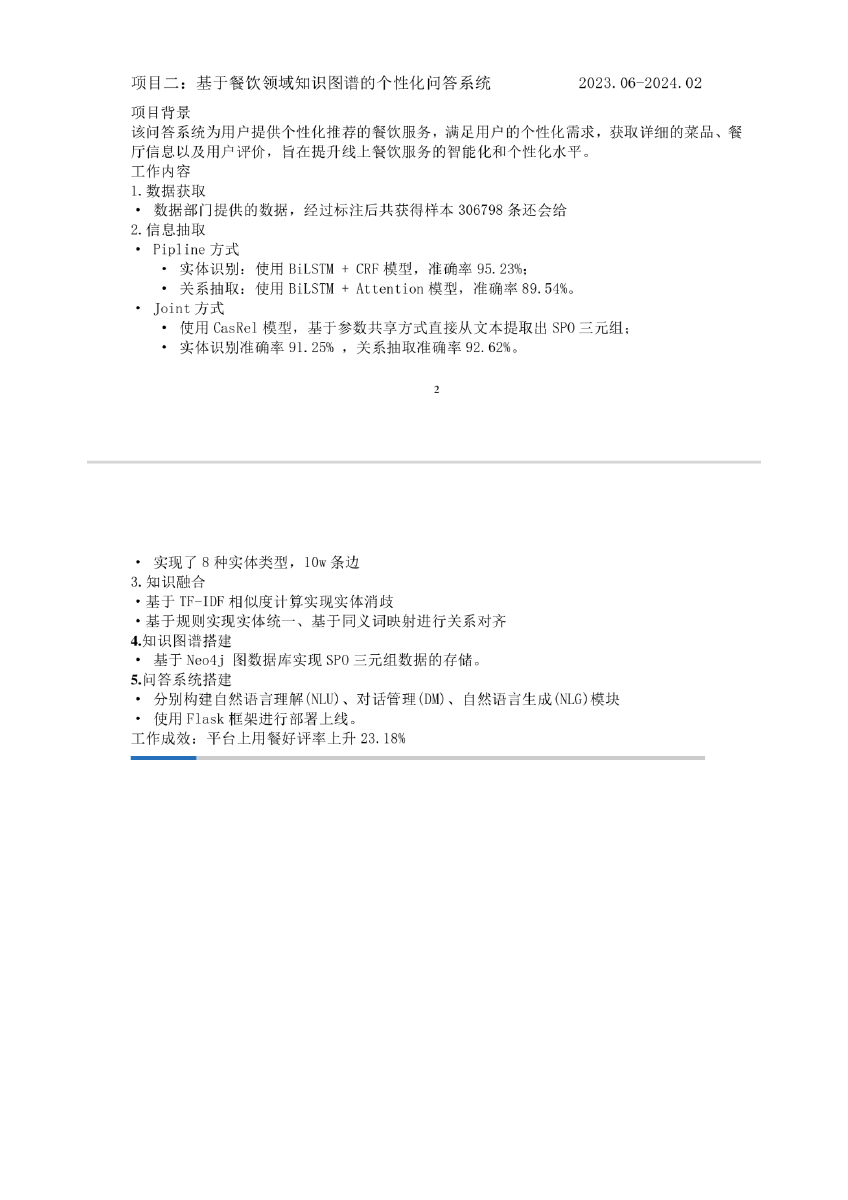

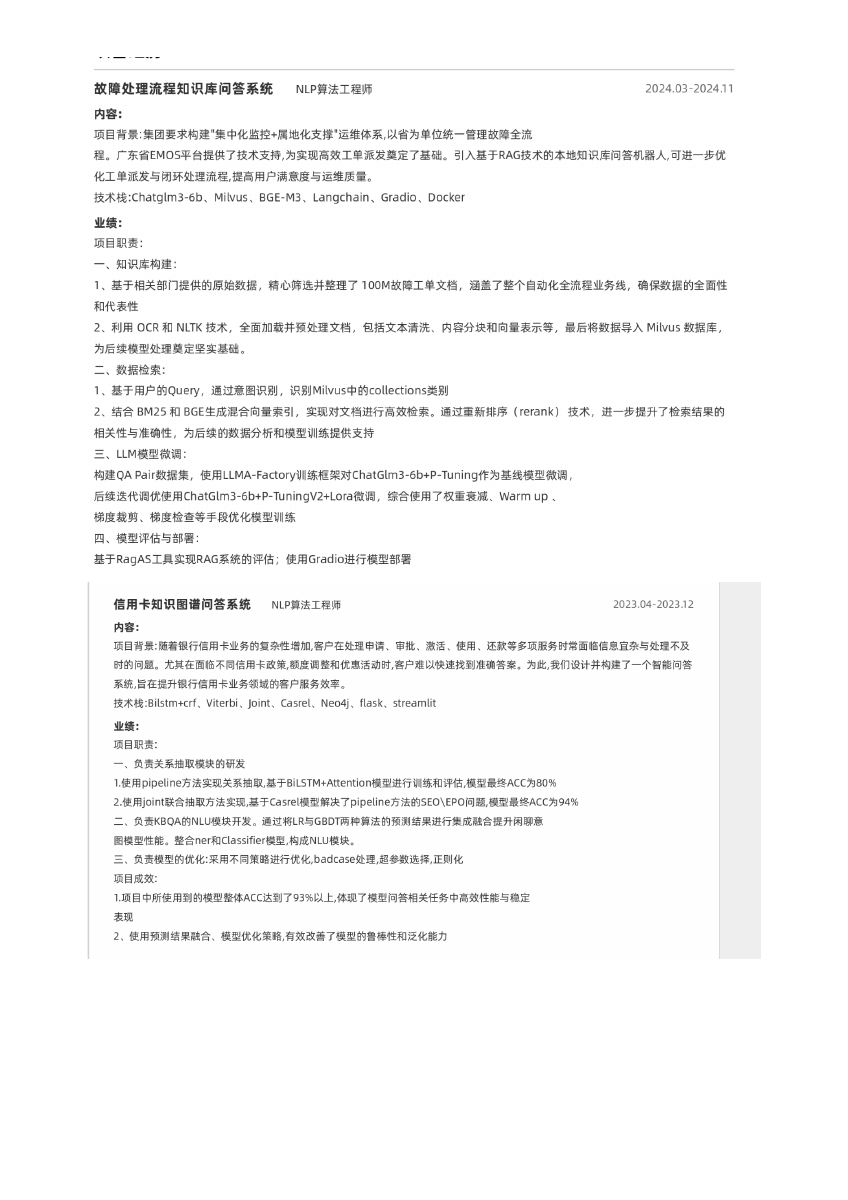

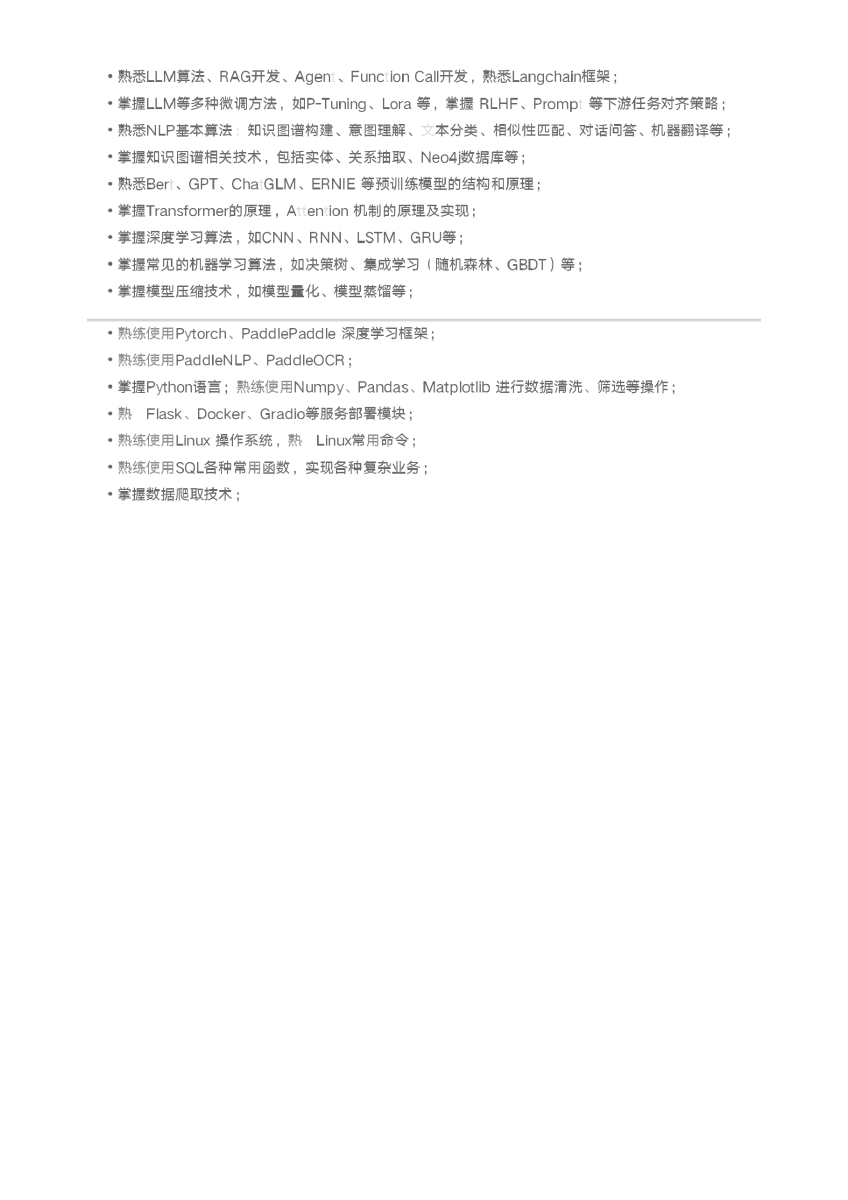

## 一、简历项目参考：怎样组织大模型项目

扫描版 PDF 里有多段算法工程师 / NLP 算法工程师项目经历。每段经历基本按以下顺序组织：

1. 项目时间、项目名称和岗位；
2. 项目背景：原有流程的痛点和目标；
3. 工作内容：数据处理、模型、检索、服务和评估；
4. 项目成果：效率、准确率、召回率或上线效果。

写项目时要把“做了什么”与“带来什么结果”放在一起，例如“使用 PaddleOCR 提取截图文本，再结合微调模型实现图文检索”，后面对应“准确率提升”或“作业效率提升”。指标必须能说明测量对象、数据规模和评价方式。

### 1.1 地图数据作业软件使用情况数据分析 Agent

项目背景是传统地图数据作业软件依赖人工，基于数据填报系统和 BI 系统统计软件使用情况，帮助分析人员做决策。项目使用 LangChain 搭建智能体，分为：

- 数据采集：通过 API 获取每个软件的使用情况；
- 数据分析：使用 ERNIE-4.0 生成数据预警和行动建议；
- 报告生成：把分析结果自动生成图文报告；
- 邮件发送：针对需要触达的人员自动发送报告。

原资料记录的成果包括数据预警有效率 86%、决策采纳率 55%，以及每周节省约 2 人/天。表达这类成果时，要明确“有效率”和“采纳率”的统计口径。

### 1.2 地图数据生产支持问答系统

项目把地图数据作业知识图谱、交通通识、智慧城市和规章制度整合为问答系统。简历中的技术链包括：

- 使用 PaddleOCR 处理约 502M 原始 PDF；
- 清洗约 1.2T 的 txt、doc、ppt 数据，去掉特殊字符和冗余信息；
- 按句子切分，使用 embedding v1 向量化，写入 Milvus 的 3 个 collection，约 145 万条；
- 对用户问题做改写和拆解，使用 LoRA 微调的 BERT 做意图识别，支持 5 种类型，资料记录 F1 约 90%；
- 结合 BM25、Embedding 和 ReRank 进行检索，使用 ERNIE-4.0 生成答案；
- 通过 RAGAS 和人工评估检查效果，资料记录 answer relevancy 约 0.85、人工 1000 条测试准确率约 90%。

这段经历的重点不是堆砌工具，而是呈现“数据治理 → 知识入库 → 意图识别 → 混合检索 → 生成 → 评估”的完整链路。

### 1.3 地图数据生产支持问答系统一期

一期项目以知识图谱和问答系统为核心：采集约 20 万条地图数据手册，包含 46 种实体、7 种关系；使用 CasRel 从文本直接抽取 SPO 三元组；用 TF-IDF 计算实体相似度做实体消歧，再用规则完成实体统一和同义词映射；最终写入 Neo4j 图数据库。

问答系统拆分为自然语言理解 NLU、对话管理 DM、自然语言生成 NLG，并使用 Flask + Docker 部署。资料记录实体识别准确率 95.1%、关系抽取准确率 92.6%、综合 F1 90.5%。

### 1.4 餐饮软件故障智能问答系统（RAG）

项目针对餐饮软件故障定位慢、排查耗时长和依赖人工经验的问题，使用约 2.6 万文档构建 RAG：

- PaddleOCR 处理图片和 PDF，清洗文档并分块；
- BGE-large 做向量化，Milvus 保存 3 个 collection；
- BERT 意图识别支持 4 种类型，资料记录 F1 约 92.3%；
- BM25 + BGE-M3 混合检索，GraphRAG 合并图谱与向量结果，增强 Prompt；
- ChatGLM3-6B 生成答案，vLLM 加速推理，Flask + Docker 上线。

项目优化点可以概括为：检索 R、增强 A、生成 G，分别对应索引、Prompt 和模型生成。资料记录系统准确率 90.6%，工作效率提升 33%。

### 1.5 餐饮领域知识图谱个性化问答系统

项目面向餐饮推荐，数据量约 306798 条。信息抽取包含两条路线：Pipeline 使用 BiLSTM + CRF 做实体识别、BiLSTM + Attention 做关系抽取；Joint 方式使用 CasRel 直接抽取 SPO。之后使用 TF-IDF 相似度和规则完成实体消歧、实体统一、同义词映射，写入 Neo4j，并拆分 NLU、DM、NLG 模块部署。

资料记录的平台差评率下降 23.18%。阅读这类项目时，要注意 Pipeline 与 Joint 的对比是方法组织方式的差异，不能只比较单个实体准确率。

### 1.6 其他简历项目

PDF 还记录了：

- 故障处理流程知识库问答系统：约 100M 故障工单文档，OCR、NLTK 清洗，Queri/collections 检索，ChatGLM3-6B + P-Tuning / P-Tuning v2 + LoRA 微调，RAGAS 评估；
- 信用卡知识图谱问答系统：BiLSTM + CRF、CasRel、Neo4j、Flask 和 Streamlit；
- 技能清单：LLM、RAG、Agent、Function Call、LangChain、P-Tuning、LoRA、RLHF、Prompt、BERT、GPT、ChatGLM、ERNIE、Transformer、CNN/RNN/LSTM/GRU、随机森林、GBDT、量化和蒸馏，以及 PyTorch、PaddlePaddle、PaddleNLP、PaddleOCR、Python、Linux、SQL。

项目表述可以从“负责某模块”继续具体到数据量、模型、评估指标和上线方式；没有测量依据的泛化形容词应删掉。

## 二、12 号代码与 11 号代码的复核

`12-代码/ptune_chatglm` 包含 `glm_config.py`、数据处理、DataLoader、`common_utils.py`、`train.py`、`inference.py` 和同一份混合 JSONL 数据。逐文件对比后，以下核心文件与 11 号目录字节一致：

- `glm_config.py`
- `data_handle/data_preprocess.py`
- `data_handle/data_loader.py`
- `utils/common_utils.py`
- `train.py`
- `inference.py`

所以 12 号没有新增训练实现。默认仍是 `use_lora=True`、`use_ptuning=False`，source/target 上限各 100，batch size 4，训练 2 轮，保存频率 200。完整代码解释和复现顺序见 11 篇；本篇把它当作分享资料的代码归档。

```python
from pathlib import Path
import hashlib

old = Path(r"D:/baidudisk/BaiduNetdiskDownload/11-代码/ptune_chatglm")
new = Path(r"D:/baidudisk/BaiduNetdiskDownload/12-代码/ptune_chatglm")
for name in ["glm_config.py", "train.py", "inference.py"]:
    same = hashlib.sha256((old / name).read_bytes()).digest() == hashlib.sha256((new / name).read_bytes()).digest()
    print(name, same)
```

## 三、大模型基础知识扩展：模型内部组件

### 3.1 激活函数

- **GELU**：用高斯分布的平滑门控替代 ReLU 的硬截断，Transformer 和 BERT 中常见；
- **SwiGLU**：用 Swish 门控线性单元，让一条分支控制另一条分支；
- **GeGLU**：用 GELU 作为门控函数，形式与 GLU 类似。

门控激活通常需要两路线性投影再逐元素相乘，参数量和隐藏维度配置要一起考虑。资料重点是理解“激活值也参与选择性传递”，不应把 SwiGLU/GeGLU 简化成普通 ReLU 的替换字符串。

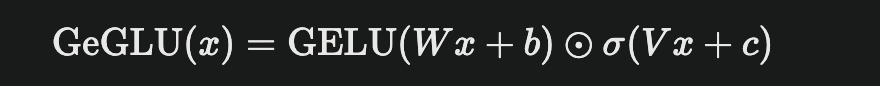

### 3.2 归一化

- **LayerNorm**：在每个样本的特征维度上计算均值和方差，再用可学习的 γ、β 缩放平移；
- **RMSNorm**：省略均值，只按均方根归一化，计算更简单，并保留均值成分；
- **DeepNorm**：为很深的 Transformer 调整残差连接缩放，把 `LayerNorm(x + Sublayer(x))` 改为带 α 的残差形式，帮助稳定深层训练。

选择归一化方式会影响数值稳定性、计算成本和深层残差的尺度，不能脱离模型架构单独比较。

### 3.3 RoPE 旋转位置编码

RoPE 对 query 和 key 的每两个维度做旋转，将位置信息融入向量内积，使注意力分数包含相对位置信息。它的基本流程是：生成位置角度，对 Q/K 两两维度旋转，再计算 attention 内积。

资料强调 RoPE 的外推性较好，已成为 decoder-only 大模型常见的位置编码方式。

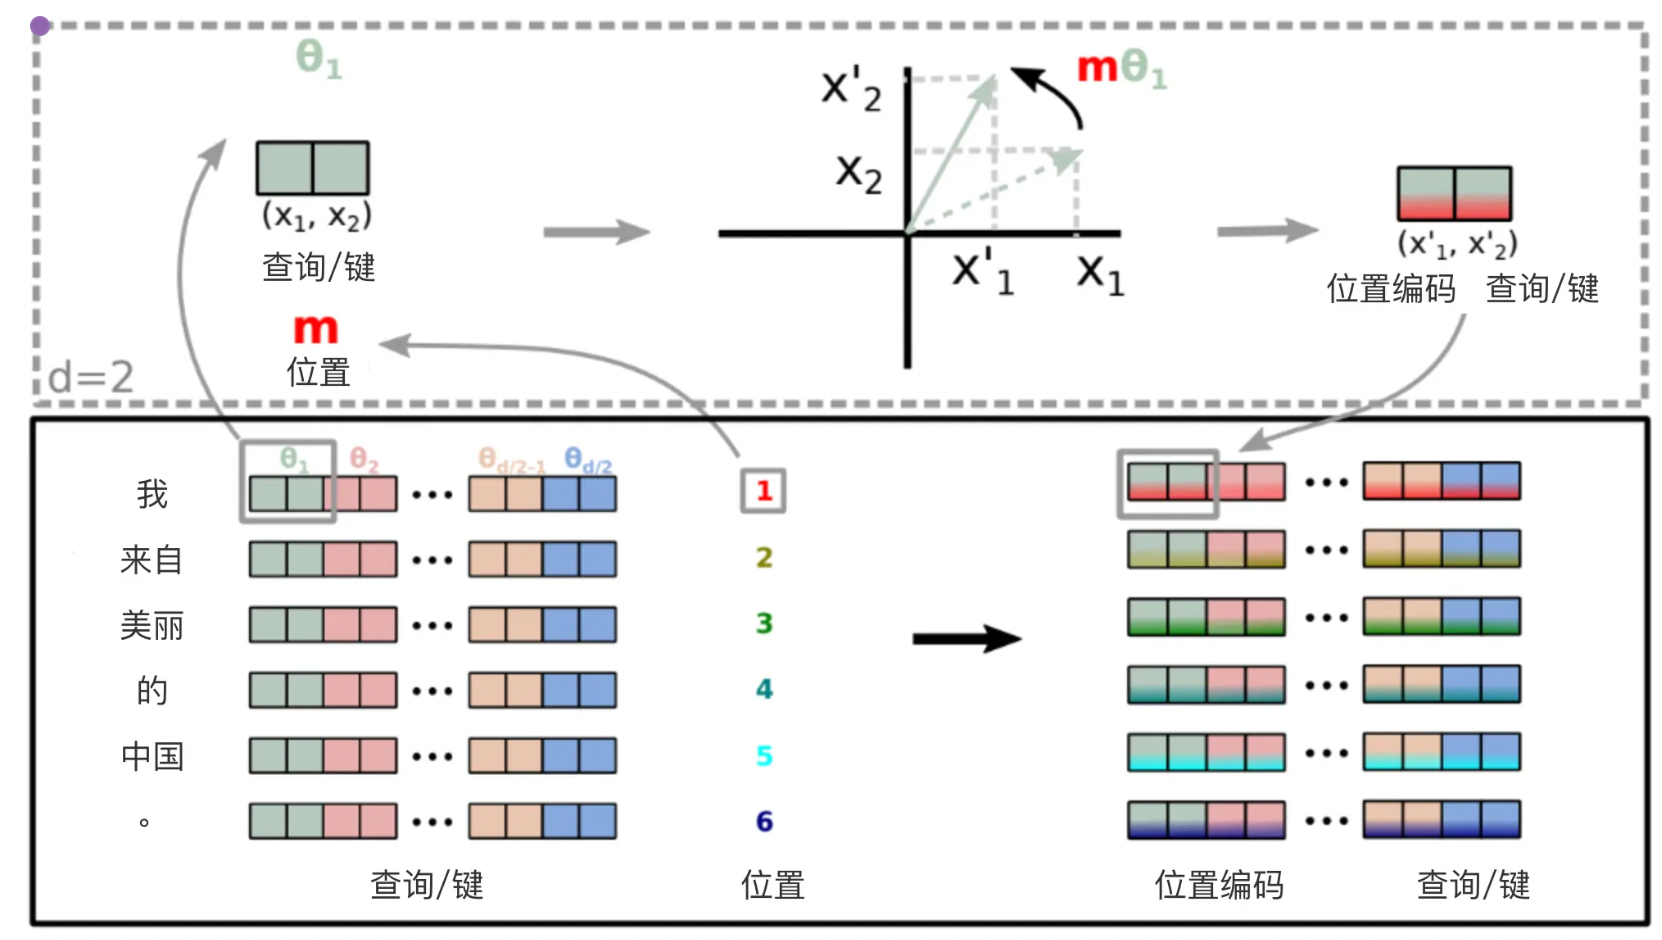

## 四、开源模型与推理效率

### 4.1 Llama 3、GLM4 和 Qwen2 资料要点

- Llama 3 仍采用 decoder-only Transformer，词表扩大到 128K，8B/70B 使用 GQA，预训练数据超过 15T token，并加入多语言数据；
- GLM4-9B 资料强调多语言、长上下文、多模态和工具调用能力；
- Qwen2 全系列使用 GQA，在速度和显存占用之间折中。

这些内容来自 12 号扩展资料的版本记录，阅读时要把它们当作课程时期的模型知识卡片，具体模型能力仍应以实际 checkpoint 和官方文档为准。

### 4.2 GQA 与 KV Cache

MHA 为每个 query 使用独立的 key/value；MQA 让所有 query 共享一组 key/value；GQA 把 query 分组，每组共享一组 key/value。GQA 在效果和推理成本之间折中。

KV Cache 保存自回归 decoder 已经计算过的 key/value。生成首 token 要处理完整输入，后续 token 可复用历史 KV：因此 TTFT（首 token 时间）通常高于 TPOT（后续 token 时间）。BERT 这类非自回归编码器通常不使用这种生成缓存。

![KV Cache示意](attachment:KV Cache示意.png)
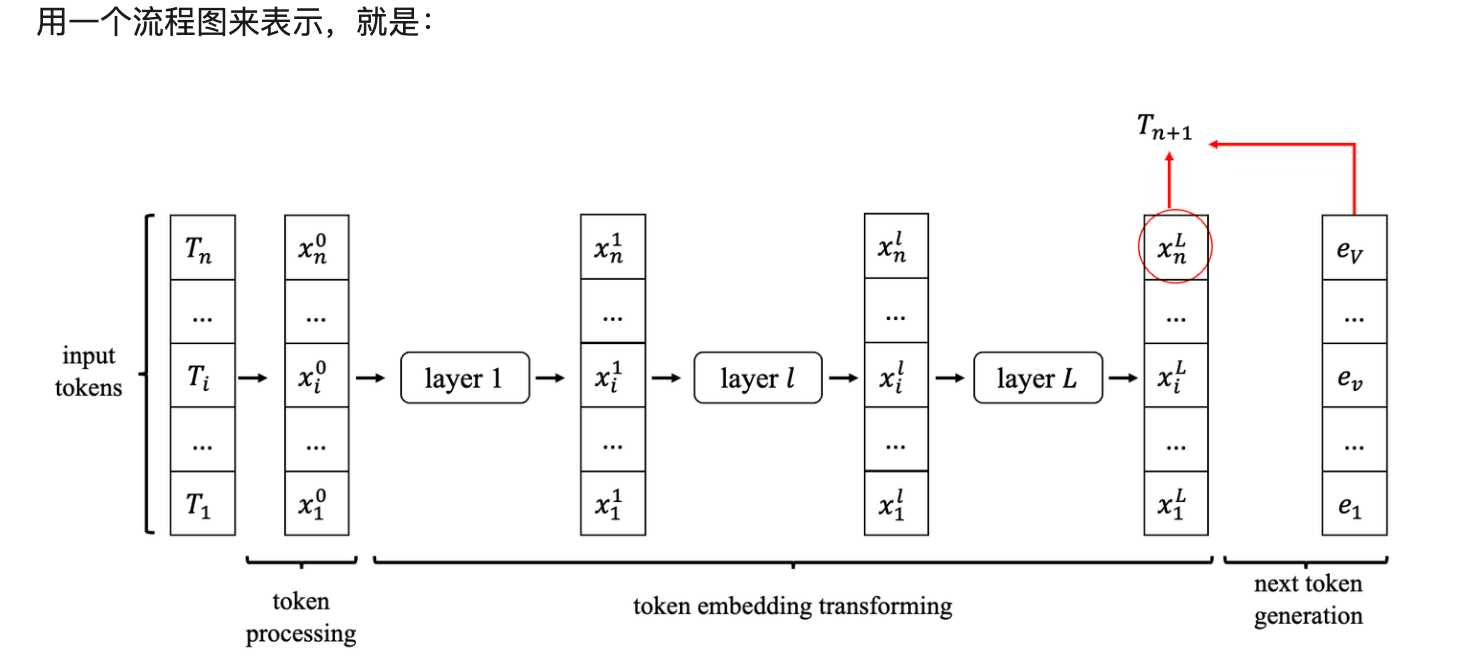

### 4.3 generate、chat 与 stream_chat

- `model.generate()` 是底层生成接口，适合批量生成，需要传入 `input_ids`、长度、采样、top-k/top-p 或 beam 参数；
- `model.chat()` 是对话模型提供的高层封装，接受 `query` 和 `history`，通常内部调用 generate；
- `model.stream_chat()` 按片段返回生成结果，适合需要较低交互等待感的页面。

接口名称不能跨模型直接套用。必须以当前模型的 remote code、tokenizer 和方法签名为准。

### 4.4 vLLM 与 PagedAttention

资料给出 Qwen2.5-7B 的 vLLM 调用流程：安装 `vllm`，加载 tokenizer，定义 `temperature`、`top_p`、`repetition_penalty`、`max_tokens`，初始化 `LLM`，调用 `generate`。

```python
from transformers import AutoTokenizer
from vllm import LLM, SamplingParams

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B-Instruct")
sampling_params = SamplingParams(temperature=0.7, top_p=0.8, repetition_penalty=1.05, max_tokens=512)
llm = LLM(model="Qwen/Qwen2.5-7B-Instruct")
outputs = llm.generate(["Tell me something about large language models."], sampling_params)
for output in outputs:
    print(output.outputs[0].text)
```

PagedAttention 把 KV Cache 切成固定大小的 block，不要求所有请求的缓存连续排布，减少碎片和浪费。vLLM 的价值是把批处理、KV Cache 和调度结合起来提高吞吐；它不是新的模型训练方法。

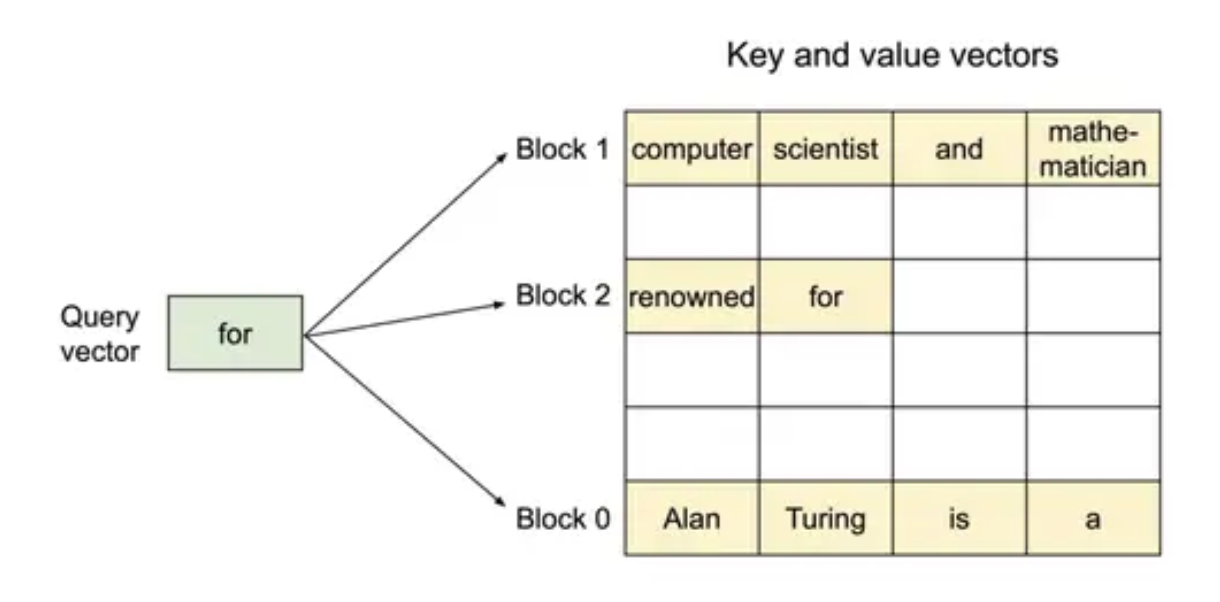

## 五、向量数据库与 RAG 扩展

### 5.1 Milvus 基本概念

Milvus 用 collection 组织向量实体，field 对应字段，schema 定义字段和向量维度。一个 collection 通常包含主键、标量字段和向量字段；向量字段必须指定维度和距离度量。

常见索引：

| 索引 | 适用特点 |
| --- | --- |
| FLAT | 暴力精确搜索，数据量较小时使用 |
| IVF_FLAT | 聚类后只搜索部分簇，`nprobe` 平衡速度与召回 |
| IVF_SQ8 | 在 IVF 基础上做标量量化，降低存储 |
| IVF_PQ | 倒排加乘积量化，适合大规模高维向量 |
| HNSW | 图索引，强调搜索效率 |

常用度量包括 L2、内积 IP 和 COSINE。索引类型、度量和 embedding 模型要匹配，不能仅凭索引名称判断效果。

### 5.2 Milvus schema 和混合检索

建库顺序是：连接服务 → 定义 Field schema → 创建 Collection schema → 创建 collection → 插入数据 → 建立索引 → load → search/query。主键字段只能有一个，向量字段要设置 `dim`，VARCHAR 要设置 `max_length`。

混合检索可以同时使用：

- BM25：关键词和词频相关，适合精确术语；
- dense embedding：语义相似，适合表达变化；
- ReRank：对初步候选进行更精细的相关性打分。

多路结果可用加权或其他 rerank 策略合并。候选数量、权重和最终 top-k 应通过验证集调参。

### 5.3 FlashAttention 与 RAG 评估

FlashAttention 通过 tiling 和重计算减少标准 Attention 中间矩阵在 HBM 的读写，降低显存访问和计算开销；它改变的是 attention 实现，不改变模型的数学目标。

RAGAS 的四个常见指标：

- Context Precision：检索上下文中有用信息的比例；
- Context Recall：是否找全回答问题所需的信息；
- Faithfulness：答案是否忠实于检索上下文；
- Answer Relevancy：答案是否回应用户问题。

RAGAS 适合初步自动评估，最终仍需人工检查事实性、完整性和可用性。资料还提到 embedding 微调可用 `(query, positive, negative)` 三元组做对比学习。

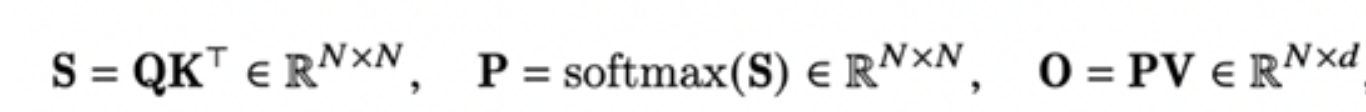

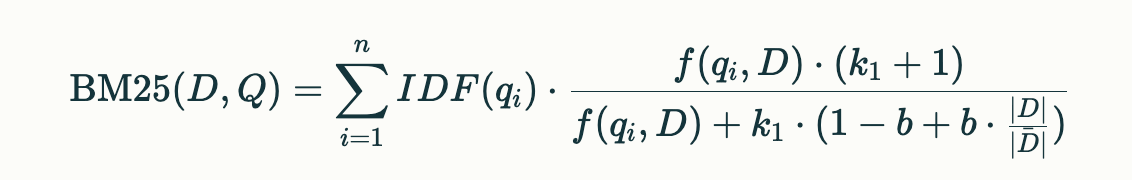

## 六、传统机器学习补充

### 6.1 TF-IDF

TF-IDF 用词频 TF 和逆文档频率 IDF 评估词在文档中的重要性：

```text
TF(t,d) = 词 t 在文档 d 中的出现次数 / 文档 d 的总词数
IDF(t) = log(语料库文档数 / 包含 t 的文档数)
TF-IDF(t,d) = TF(t,d) × IDF(t)
```

常见词在很多文档中出现，IDF 较低；只在少数文档出现的词，IDF 较高。简历项目中 TF-IDF 被用于实体消歧、关键词和相似度计算，但它无法像大模型 embedding 那样直接表达复杂语义。

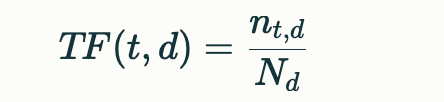

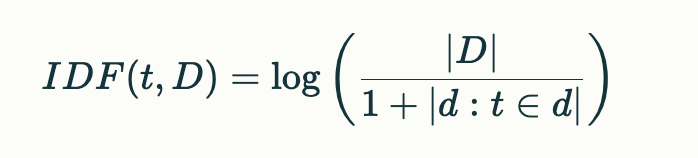

### 6.2 Bagging、Boosting 与 GBDT

集成学习不是一个单独算法，而是组合多个基础模型的训练思路：

- **Bagging**：有放回抽样训练多个相互独立的模型，分类投票、回归取均值；随机森林就是 bagging + 决策树；
- **Boosting**：按轮次关注前一轮预测错误的样本，让模型逐步组合成强模型；
- **GBDT**：每棵树拟合当前预测的残差或负梯度，所有树的输出相加得到最终预测。

GBDT 的“下一棵树拟合剩余误差”是理解算法的关键；实际实现中通常使用损失函数对预测值的负梯度近似残差。

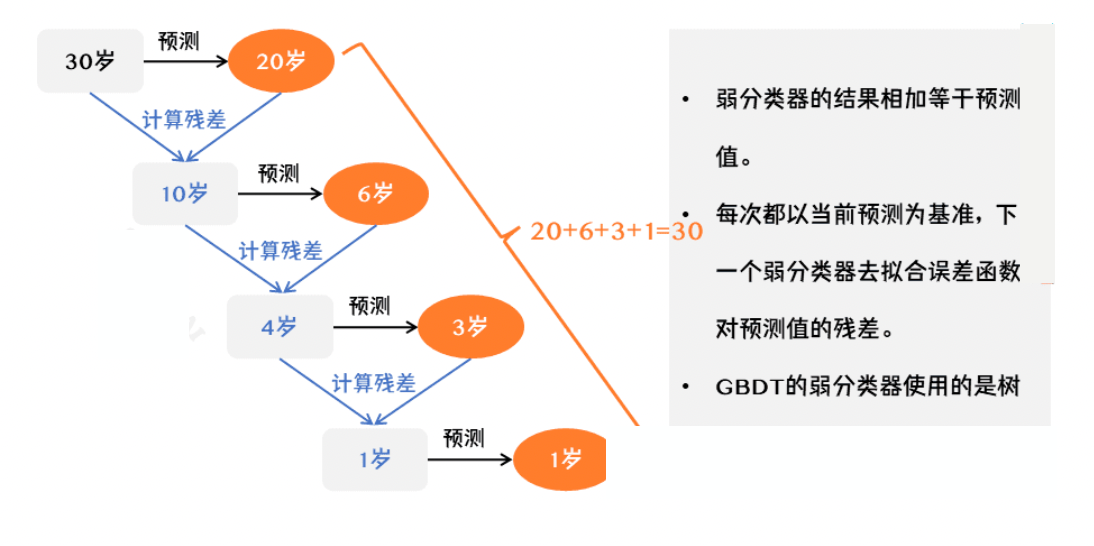

## 七、大模型强化学习与 RLHF

### 7.1 强化学习基本概念

强化学习包含 Agent 和 Environment。状态空间为 S，动作空间为 A，奖励为 R。Agent 观察当前状态和奖励，选择动作，环境转移到下一状态并反馈新奖励。价值函数不只看即时奖励：

```text
V_t = R_t + γ V_{t+1}
```

这体现“现在的动作会影响未来收益”。LLM 生成时可以把每个 token 看作动作，把整句回答的质量看作奖励。

### 7.2 RLHF 的四个角色

- **Actor / Policy**：当前正在训练、负责生成回答的模型；
- **Reference**：冻结的参考模型，约束 Actor 不要偏离 SFT 模型太远；
- **Reward Model**：根据人类偏好给生成结果打分，RL 阶段冻结；
- **Critic / Value**：估计状态价值，帮助计算 advantage，通常与 Actor 一起更新。

标准 PPO 需要同时装载四个大模型，显存和通信压力很大。Reward 是即时质量信号，Critic 估计包含未来收益的价值，两者不能简单互相替代。

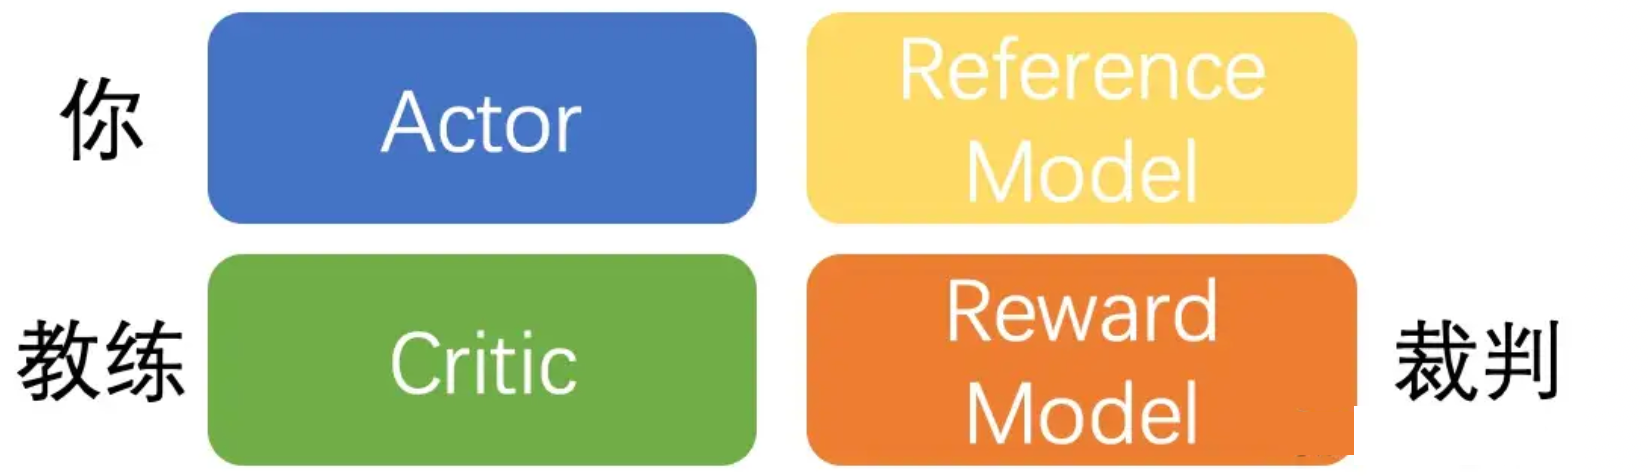

### 7.3 PPO 的核心思路

Actor loss 通过 advantage 判断某个动作是否比预期好，并使用 importance ratio 和 clip 限制新旧策略变化。Critic loss 让价值模型拟合由 reward 和下一状态价值构成的目标。Reference 与 Actor 的 KL 惩罚用于控制策略漂移，降低 reward hacking 和训练发散风险。

PPO 的优点是 on-policy，训练样本由当前模型生成，数据分布匹配；缺点是生成成本高、模型数量多、训练步骤慢。

### 7.4 降低 PPO 成本的 On-policy 方法

- **ReMax**：去掉 Critic，用当前策略 greedy 生成的结果分数作为 baseline，比较探索采样和 greedy 采样的 reward；
- **GRPO**：对同一个 prompt 采样多个答案，用组内均值和标准差标准化 reward 作为 advantage，保留 PPO 的 ratio/clip 思路并加 KL 惩罚。

GRPO 省掉 Critic，但需要同一 prompt 采样足够多答案；如果 SFT 输出本来就很分散，组内均值的方差会影响训练稳定性。

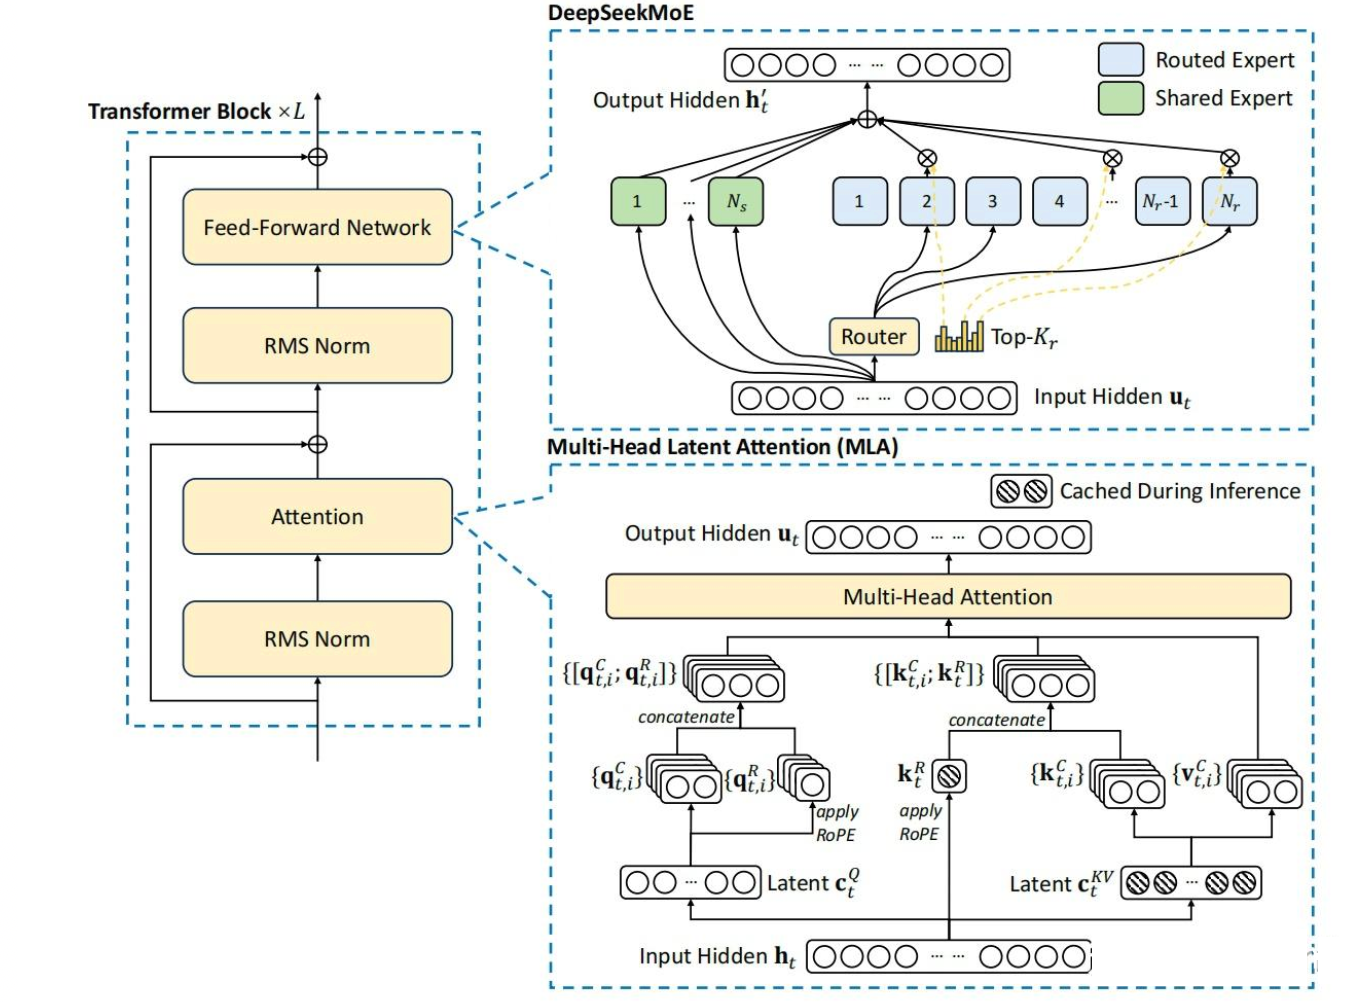

### 7.5 Offline 偏好优化

Offline 方法不让模型在训练中持续生成，而是使用同一 prompt 的 chosen / rejected 回答对：

- **DPO**：提高 chosen 相对 rejected 的策略概率，并用 reference 概率差构造对比 loss；
- **DPOP**：在 DPO 上保护 chosen 概率，降低“好坏答案概率同时下降”的风险；
- **TDPO**：加入 token-level KL 惩罚，资料强调使用 forward KL；
- **ORPO**：去掉 reference model，把 chosen 的 SFT loss 与 chosen/rejected 的 odds ratio loss 合并。

Online 方法通常更耗卡但样本与当前策略匹配，Offline 方法训练更简单、更省资源，但依赖偏好数据是否覆盖模型自身能力范围。

## 八、本篇的实践检查清单

1. 简历项目：能说清背景、数据、模型、检索、部署和指标，不把工具名称当作项目成果；
2. 模型组件：能解释激活函数、归一化、RoPE、GQA 和 KV Cache 的作用；
3. 推理服务：区分 `generate`、`chat`、`stream_chat`，知道 vLLM 和 PagedAttention 解决吞吐/缓存问题；
4. RAG：理解 BM25、embedding、Milvus、ReRank 和 RAGAS 的位置；
5. 强化学习：分清 PPO 的 Actor、Critic、Reward、Reference，以及 DPO 等 Offline 方法；
6. 代码复核：12 号 ChatGLM 代码与 11 号一致，默认仍是 LoRA，不要误写成新增 P-Tuning 训练实现。

本篇分享资料没有新增可运行训练入口，也没有在当前电脑安装 Milvus、vLLM 或运行 RLHF。所有指标和项目效果均按源文件原样整理。